### Dry Run: Template Repetition

This experiment evaluates a controlled template-repetition defect using the UCI SMS Spam Collection. The objective of this first stage is to prepare a clean baseline, inject a known defect, and verify that the resulting dataset is suitable for the subsequent representation and metric-comparison pipeline.

For this initial dry run, template repetition is implemented as exact repetition of real messages. A controlled fraction of messages is replaced with a repeated message from the same class, while dataset size and class labels are preserved.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import src
from src.defects import inject_template_repetition

In [2]:
data_path = (
    Path(src.__file__).resolve().parent.parent
    / "data"
    / "raw"
    / "SMSSpamCollection"
)

clean = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "text"]
)

print("Dataset size:", len(clean))
print("\nClass distribution:")
print(clean["label"].value_counts())

display(clean.head())

Dataset size: 5572

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


##### Inject Template Repetition

The defect is introduced by replacing a controlled fraction of messages with a repeated message selected from the same class. The injection uses a fixed random seed for reproducibility and records every modified row in an audit table.

For the first dry run, the selected severity is 30%. This percentage represents the fraction of rows intentionally replaced, not the final percentage of exact duplicates in the dataset.

In [3]:
defective, audit = inject_template_repetition(
    clean,
    severity=0.30,
    seed=42
)

print("Dataset size:", len(defective))
print("Injected rows:", audit["injected"].sum())
print("Actual severity:", audit["injected"].mean())

print("\nClass distribution:")
print(defective["label"].value_counts())


Dataset size: 5572
Injected rows: 1672
Actual severity: 0.30007178750897345

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


The audit table is used to verify that the injection was applied as intended. It records the original message, the replacement text, and the source row of the repeated message. These fields are used only for traceability and will not be provided as input to the fidelity metrics.

In [4]:
display(
    audit.loc[audit["injected"], [
        "row_id",
        "label",
        "original_text",
        "defective_text",
        "template_source_row"
    ]].head(15)
)

,row_id,label,original_text,defective_text,template_source_row
13,13,ham,I've been searching for the right words to tha...,Just sent it. So what type of food do you like?,279
26,26,ham,Lol your always so convincing.,Just sent it. So what type of food do you like?,279
27,27,ham,Did you catch the bus ? Are you frying an egg ...,Just sent it. So what type of food do you like?,279
28,28,ham,"I'm back &amp; we're packing the car now, I'll...",Just sent it. So what type of food do you like?,279
29,29,ham,Ahhh. Work. I vaguely remember that! What does...,Just sent it. So what type of food do you like?,279
30,30,ham,"Wait that's still not all that clear, were you...",Just sent it. So what type of food do you like?,279
31,31,ham,Yeah he got in at 2 and was v apologetic. n ha...,Just sent it. So what type of food do you like?,279
33,33,ham,For fear of fainting with the of all that hous...,Just sent it. So what type of food do you like?,279
36,36,ham,"Oops, I'll let you know when my roommate's done",Just sent it. So what type of food do you like?,279
41,41,ham,"Did I forget to tell you ? I want you , I need...",Just sent it. So what type of food do you like?,279


In [5]:
def repetition_summary(df, text_col="text"):
    return pd.Series({
        "messages": len(df),
        "unique_messages": df[text_col].nunique(),
        "duplicate_rate": df[text_col].duplicated().mean()
    })


summary = pd.DataFrame({
    "Clean": repetition_summary(clean),
    "Defective": repetition_summary(defective)
}).T

display(summary)

,messages,unique_messages,duplicate_rate
Clean,5572.0,5169.0,0.072326
Defective,5572.0,3684.0,0.338837


Severity increase experiment

The injection is then generated at severity levels of 0%, 10%, 30%, and 60% to prepare the datasets for the first sensitivity analysis.

In [6]:
severities = [0.0, 0.10, 0.30, 0.60]

injection_results = {}

for severity in severities:

    defective_s, audit_s = inject_template_repetition(
        clean,
        severity=severity,
        seed=42
    )

    injection_results[severity] = {
        "defective": defective_s,
        "audit": audit_s
    }

    print(
        f"Severity: {severity:.0%} | "
        f"Injected: {audit_s['injected'].sum()} | "
        f"Actual: {audit_s['injected'].mean():.4f}"
    )

Severity: 0% | Injected: 0 | Actual: 0.0000
Severity: 10% | Injected: 557 | Actual: 0.1000
Severity: 30% | Injected: 1672 | Actual: 0.3001
Severity: 60% | Injected: 3343 | Actual: 0.6000


#### Preliminary Conclusion: Defect Injection

The first stage of the dry run successfully prepared the clean baseline and generated controlled versions of the UCI SMS Spam Collection with exact template repetition. The original dataset contains 5,572 messages, including 4,825 ham and 747 spam messages. At the selected severity of 30%, the injection replaced 1,672 messages, corresponding to an actual replacement proportion of approximately 30.01%. The total number of messages and the class distribution remained unchanged.

Inspection of the audit table confirmed that multiple original messages were replaced with the same real message from their corresponding class. The experiment also generated the planned severity levels of 0%, 10%, 30%, and 60%, corresponding to 0, 557, 1,672, and 3,343 replaced messages, respectively. These results confirm that the injection mechanism can produce controlled replacement proportions and preserve the basic dataset structure.

However, this implementation represents an intentionally strong form of exact repetition. Because one repeated message is selected per class, the injection also changes the content and lexical distribution of the replaced messages. Therefore, any difference detected later cannot automatically be attributed exclusively to repetition. This limitation will be documented when interpreting the metric results.

Additionally, the current implementation does not guarantee that the same template or the same affected rows are preserved across different severity levels. This is acceptable for the initial pipeline sanity check, but a fixed injection plan will be needed for a strictly paired sensitivity experiment.

No conclusions about C2ST, MMD, or Energy Distance can be drawn at this stage because the numerical representation and statistical tests have not yet been applied. The next step is to transform the clean and defective messages using a shared TF-IDF representation and then evaluate all three metrics under the same experimental conditions.


### Representations

In [7]:
from src.representations import make_tfidf_vectorizer
from time import perf_counter

In [8]:
# adjust td-idf on the clean dataset 
vectorizer = make_tfidf_vectorizer()

start = perf_counter()

X_clean = vectorizer.fit_transform(clean["text"])

print("Clean shape:", X_clean.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print(f"Fit time: {perf_counter() - start:.2f} seconds")

Clean shape: (5572, 5000)
Vocabulary size: 5000
Fit time: 0.56 seconds


In [9]:
# transform the defective one 
start = perf_counter()

X_defective = vectorizer.transform(defective["text"])

print("Defective shape:", X_defective.shape)
print(f"Transform time: {perf_counter() - start:.2f} seconds")

assert X_clean.shape == X_defective.shape

Defective shape: (5572, 5000)
Transform time: 0.23 seconds


In [10]:
print("Matrix type:", type(X_clean))
print("Number of features:", X_clean.shape[1])

print("\nFirst 20 vocabulary terms:")
print(vectorizer.get_feature_names_out()[:20])

Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Number of features: 5000

First 20 vocabulary terms:
['00' '00 sub' '000' '000 bonus' '000 cash' '000 prize' '02' '02 06' '03'
 '03 this' '04' '05' '06' '06 03' '0800' '0800 542' '08000839402'
 '08000839402 or' '08000930705' '08000930705 for']


#### TF-IDF Representation

The TF-IDF configuration uses unigrams and bigrams to capture both individual words and short repeated phrases, while the 5,000-feature limit keeps the representation computationally manageable for the dry run. Lowercasing, L2 normalization, and retaining stop words provide consistent preprocessing without removing potentially useful template patterns. These settings are a practical starting point, not an optimal configuration established by the results. In the final experiment, if training and evaluation splits are used, the vectorizer should be fitted only on the training data and then applied to the evaluation data to avoid information leakage.

The first 20 vocabulary terms confirm that the representation includes both individual tokens and consecutive token pairs.

The shared vectorizer ensures that clean and defective messages are represented in the same feature space. This completes the representation stage of the dry run. The next step is to apply C2ST, MMD, and Energy Distance to these matrices under the same experimental conditions.


In [11]:
from src.metrics import (
    c2st,
    mmd2_unbiased,
    mmd_permutation_test,
    energy_distance_statistic,
    energy_permutation_test
)

In [12]:
seed = 42
n = 100

rng = np.random.default_rng(seed)

# Disjoint original row indices for the two samples.
indices = rng.permutation(len(clean))

idx_clean = indices[:n]
idx_defective = indices[n:2*n]

P = X_clean[idx_clean]
Q = X_defective[idx_defective]

print("P shape:", P.shape)
print("Q shape:", Q.shape)
print("P type:", type(P))
print("Q type:", type(Q))

P shape: (100, 5000)
Q shape: (100, 5000)
P type: <class 'scipy.sparse._csr.csr_matrix'>
Q type: <class 'scipy.sparse._csr.csr_matrix'>


In [13]:
from time import perf_counter

start = perf_counter()

c2st_result = c2st(
    P,
    Q,
    test_size=0.5,
    seed=42,
    alpha=0.05
)

print(c2st_result)
print(f"Runtime: {perf_counter() - start:.2f} seconds")

{'accuracy': 0.62, 'p_value': 0.01048936783892586, 'reject_H0': True, 'correct': 62, 'n_test': 100, 'seed': 42}
Runtime: 0.10 seconds


In [14]:
start = perf_counter()

mmd_result = mmd_permutation_test(
    P,
    Q,
    sigma=1.0,
    n_permutations=200,
    seed=42,
    alpha=0.05
)

print(mmd_result)
print(f"Runtime: {perf_counter() - start:.2f} seconds")

{'statistic': 0.03781275513650617, 'p_value': 0.004975124378109453, 'reject_H0': True, 'n_permutations': 200, 'seed': 42}
Runtime: 0.13 seconds


In [15]:
start = perf_counter()

energy_result = energy_permutation_test(
    P,
    Q,
    n_permutations=200,
    seed=42,
    alpha=0.05
)

print(energy_result)
print(f"Runtime: {perf_counter() - start:.2f} seconds")

{'statistic': 0.08498750256025422, 'p_value': 0.004975124378109453, 'reject_H0': True, 'n_permutations': 200, 'seed': 42}
Runtime: 0.14 seconds


| Metric              |                  Result |     p-value | Reject ($H_0$)? |
| ------------------- | ----------------------: | ----------: | --------------- |
| **C2ST**            |     Accuracy = **0.62** |  **0.0105** | Yes             |
| **MMD**             |      MMD² = **0.03781** | **0.00498** | Yes             |
| **Energy Distance** | Statistic = **0.08499** | **0.00498** | Yes             |


#### Dry-run result
Under identical conditions—100 observations per group, 30% template-repetition severity, and the same 5,000-dimensional TF-IDF representation—all three tests rejected the null hypothesis. C2ST obtained an accuracy of 0.62 $(p=0.0105)$, while MMD and Energy Distance both produced permutation $p$-values of 0.00498. The latter corresponds to the minimum attainable p-value with 200 permutations, so the equal p-values should not be interpreted as equal metric sensitivity. These results confirm that the complete text -> representation -> metric pipeline is operational, but a single run is insufficient to estimate detection power or compare the metrics reliably.



#### Power Estimate Experiment

The next step is to estimate the detection power of C2ST, MMD, and Energy Distance for the same template-repetition defect. The experiment will be repeated multiple times using new random subsets $P$ and $Q$ in each repetition. Within a given repetition, all three metrics will receive exactly the same $P$ and $Q$ samples, so the only thing that changes is the metric being applied.

For each metric, power will be estimated as:

$$ \widehat{\text{Power}} = \frac{\text{number of times }H_0\text{ is rejected}}{\text{total number of repetitions}} $$

This paired design allows a fair comparison because C2ST, MMD, and Energy Distance are tested under exactly the same data conditions in every repetition.

**Keep the exact same configuration:**

- Template Repetition = 30%
- $n=100$ 
- TF-IDF = 5,000 features
- 100 reps
- MMD/Energy = 100 permutations
- $\alpha=0.05$
- every repetition recieves the same P and Q


In [16]:
# Power Estimate — 30% Template Repetition
from src.metrics import (
    c2st,
    mmd_permutation_test,
    energy_permutation_test
)


In [17]:
# Experimental configuration
N = 100
N_REPS = 100
N_PERMUTATIONS = 100
ALPHA = 0.05
BASE_SEED = 42

print("Sample size per group:", N)
print("Repetitions:", N_REPS)
print("Permutations for MMD/Energy:", N_PERMUTATIONS)
print("Alpha:", ALPHA)

Sample size per group: 100
Repetitions: 100
Permutations for MMD/Energy: 100
Alpha: 0.05


In [18]:
# check the matrices 
print("Clean:", X_clean.shape)
print("Defective:", X_defective.shape)

assert X_clean.shape == X_defective.shape
assert X_clean.shape[1] == 5000

Clean: (5572, 5000)
Defective: (5572, 5000)


**Run the 100 reps**
Each rep:
- Generate new index permutation
- take 100 clean messages for $P$
- take another 100 different indexes for $Q$
- all of the metrics receive the exact same $P,Q$
- register p-value, statistic and rejection

In [19]:
results = []

total_start = perf_counter()

for rep in range(N_REPS):

    rep_seed = BASE_SEED + rep
    rng = np.random.default_rng(rep_seed)

    # Shuffle all row indices.
    indices = rng.permutation(X_clean.shape[0])

    # Use disjoint original rows for P and Q.
    idx_P = indices[:N]
    idx_Q = indices[N:2*N]

    P = X_clean[idx_P]
    Q = X_defective[idx_Q]

    # -------------------------------------------------
    # C2ST
    # -------------------------------------------------
    start = perf_counter()

    c2st_result = c2st(
        P,
        Q,
        test_size=0.5,
        seed=rep_seed,
        alpha=ALPHA
    )

    c2st_time = perf_counter() - start

    results.append({
        "rep": rep + 1,
        "seed": rep_seed,
        "metric": "C2ST",
        "statistic": c2st_result["accuracy"],
        "p_value": c2st_result["p_value"],
        "reject_H0": c2st_result["reject_H0"],
        "runtime_seconds": c2st_time
    })

    # -------------------------------------------------
    # MMD
    # -------------------------------------------------
    start = perf_counter()

    mmd_result = mmd_permutation_test(
        P,
        Q,
        sigma=1.0,
        n_permutations=N_PERMUTATIONS,
        seed=rep_seed,
        alpha=ALPHA
    )

    mmd_time = perf_counter() - start

    results.append({
        "rep": rep + 1,
        "seed": rep_seed,
        "metric": "MMD",
        "statistic": mmd_result["statistic"],
        "p_value": mmd_result["p_value"],
        "reject_H0": mmd_result["reject_H0"],
        "runtime_seconds": mmd_time
    })

    # -------------------------------------------------
    # Energy Distance
    # -------------------------------------------------
    start = perf_counter()

    energy_result = energy_permutation_test(
        P,
        Q,
        n_permutations=N_PERMUTATIONS,
        seed=rep_seed,
        alpha=ALPHA
    )

    energy_time = perf_counter() - start

    results.append({
        "rep": rep + 1,
        "seed": rep_seed,
        "metric": "Energy Distance",
        "statistic": energy_result["statistic"],
        "p_value": energy_result["p_value"],
        "reject_H0": energy_result["reject_H0"],
        "runtime_seconds": energy_time
    })

    # Progress indicator every 10 repetitions.
    if (rep + 1) % 10 == 0:
        print(f"Completed {rep + 1}/{N_REPS} repetitions")


total_runtime = perf_counter() - total_start

results_df = pd.DataFrame(results)

print("\nExperiment completed.")
print(f"Total runtime: {total_runtime:.2f} seconds")

Completed 10/100 repetitions
Completed 20/100 repetitions
Completed 30/100 repetitions
Completed 40/100 repetitions
Completed 50/100 repetitions
Completed 60/100 repetitions
Completed 70/100 repetitions
Completed 80/100 repetitions
Completed 90/100 repetitions
Completed 100/100 repetitions

Experiment completed.
Total runtime: 9.06 seconds


In [20]:
display(results_df.head(12))

,rep,seed,metric,statistic,p_value,reject_H0,runtime_seconds
0,1,42,C2ST,0.620000,0.010489,True,0.040960
1,1,42,MMD,0.037813,0.009901,True,0.057723
2,1,42,Energy Distance,0.084988,0.009901,True,0.046190
3,2,43,C2ST,0.640000,0.003319,True,0.013318
4,2,43,MMD,0.047166,0.009901,True,0.034630
5,2,43,Energy Distance,0.105952,0.009901,True,0.027943
6,3,44,C2ST,0.680000,0.000204,True,0.017363
7,3,44,MMD,0.033634,0.009901,True,0.029219
8,3,44,Energy Distance,0.075049,0.009901,True,0.036477
9,4,45,C2ST,0.670000,0.000437,True,0.012330


In [21]:
#power calculation 
power_summary = (
    results_df
    .groupby("metric")
    .agg(
        rejections=("reject_H0", "sum"),
        repetitions=("reject_H0", "count"),
        power=("reject_H0", "mean"),
        mean_p_value=("p_value", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean")
    )
    .reset_index()
)

display(power_summary)

,metric,rejections,repetitions,power,mean_p_value,mean_runtime_seconds
0,C2ST,85,100,0.85,0.017672,0.015093
1,Energy Distance,100,100,1.00,0.009901,0.036991
2,MMD,100,100,1.00,0.009901,0.037687


| Metric              | Rejections | Estimated power | Interpretation                                            |
| ------------------- | ---------: | --------------: | --------------------------------------------------------- |
| **C2ST**            |   85 / 100 |        **0.85** | Detected the 30% repetition defect in 85% of repetitions. |
| **MMD**             |  100 / 100 |        **1.00** | Detected the defect in every repetition.                  |
| **Energy Distance** |  100 / 100 |        **1.00** | Detected the defect in every repetition.                  |



**Monte Carlo Uncertainty:** The estimated power is based on a finite number of repetitions, so it can vary slightly if the experiment is repeated with different random samples. The Monte Carlo standard error measures this simulation uncertainty. For example, a power estimate of 0.85 obtained from 100 repetitions does not mean that the true detection probability is exactly 0.85; another set of 100 repetitions could produce a slightly different value. This uncertainty decreases as the number of repetitions increases.

In [22]:
# add montecarlo uncertainty 
power_summary["mc_se"] = np.sqrt(
    power_summary["power"]
    * (1 - power_summary["power"])
    / power_summary["repetitions"]
)

power_summary["ci95_lower"] = (
    power_summary["power"]
    - 1.96 * power_summary["mc_se"]
).clip(0, 1)

power_summary["ci95_upper"] = (
    power_summary["power"]
    + 1.96 * power_summary["mc_se"]
).clip(0, 1)

display(
    power_summary[
        [
            "metric",
            "rejections",
            "repetitions",
            "power",
            "mc_se",
            "ci95_lower",
            "ci95_upper"
        ]
    ]
)

,metric,rejections,repetitions,power,mc_se,ci95_lower,ci95_upper
0,C2ST,85,100,0.85,0.035707,0.780014,0.919986
1,Energy Distance,100,100,1.00,0.000000,1.000000,1.000000
2,MMD,100,100,1.00,0.000000,1.000000,1.000000


In [23]:
# summary
stat_summary = (
    results_df
    .groupby("metric")
    .agg(
        mean_statistic=("statistic", "mean"),
        std_statistic=("statistic", "std"),
        median_p_value=("p_value", "median")
    )
    .reset_index()
)

display(stat_summary)

,metric,mean_statistic,std_statistic,median_p_value
0,C2ST,0.635400,0.039528,0.006016
1,Energy Distance,0.094057,0.028617,0.009901
2,MMD,0.041949,0.012757,0.009901


In [24]:
results_df.to_csv(
    "../results/power_template_repetition_30pct_n100.csv",
    index=False
)

power_summary.to_csv(
    "../results/power_template_repetition_30pct_n100_summary.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.



MMD and Energy were more consistently sensitive than C2ST. This supports the initial prediction that MMD would be specially sensitive to Template Repetition. 

MMD and Energy both obtained 100/100 rejections and all their p-values were: 

$$ 0.009901=\frac{1}{100+1} $$

which is the lowest possible p-value with 100 permutation. Both test are saturated at this severity level, it is impossible to know if one is more sinsitive than other.  

MMD and Energy Distance showed higher detection power than C2ST for this particular defect, representation, sample size, and severity.

### Power Estimate Results — 30% Template Repetition. 

Over 100 paired repetitions, C2ST rejected the null hypothesis in 85 cases, corresponding to an estimated power of 0.85. MMD and Energy Distance rejected the null hypothesis in all 100 repetitions, giving estimated powers of 1.00 under this configuration. All three metrics received exactly the same $P$ and $Q$ subsets within each repetition, so the observed differences reflect their behavior under matched experimental conditions. The results suggest that MMD and Energy Distance are more consistently sensitive than C2ST to 30% exact template repetition in the selected TF-IDF representation. However, MMD and Energy Distance cannot yet be ranked because both reached maximum observed power and their permutation p-values were limited by the 100-permutation resolution. These findings apply only to the current defect, representation, sample size, and severity and should not be interpreted as evidence that one metric is universally superior.

#### Sensitivity Curve — Template Repetition

The sensitivity experiment evaluates how the detection probability of C2ST, MMD, and Energy Distance changes as template-repetition severity increases. The same sample size, TF-IDF representation, number of repetitions, and test configuration are used at every severity level. Within each repetition, all three metrics receive exactly the same $P$ and $Q$ samples. The 0% severity level represents the null condition and is used to estimate Type I error, while 10%, 30%, and 60% are used to estimate detection power.

In [25]:
# transform severities with the same td-idf
severities = [0.0, 0.10, 0.30, 0.60]

X_by_severity = {}

for severity in severities:

    defective_s = injection_results[severity]["defective"]

    X_s = vectorizer.transform(
        defective_s["text"]
    )

    X_by_severity[severity] = X_s

    print(
        f"Severity {severity:.0%}: "
        f"{X_s.shape}"
    )

Severity 0%: (5572, 5000)
Severity 10%: (5572, 5000)
Severity 30%: (5572, 5000)
Severity 60%: (5572, 5000)


In [26]:
sensitivity_results = []

total_start = perf_counter()

for severity in severities:

    X_Q = X_by_severity[severity]

    audit_s = injection_results[severity]["audit"]

    severity_start = perf_counter()

    for rep in range(N_REPS):

        rep_seed = BASE_SEED + rep
        rng = np.random.default_rng(rep_seed)

        indices = rng.permutation(
            X_clean.shape[0]
        )

        # Disjoint original rows
        idx_P = indices[:N]
        idx_Q = indices[N:2*N]

        P = X_clean[idx_P]
        Q = X_Q[idx_Q]

        # Actual proportion of injected rows
        # inside this particular Q sample
        sample_defect_rate = (
            audit_s
            .loc[idx_Q, "injected"]
            .mean()
        )

        # -----------------------------------------
        # C2ST
        # -----------------------------------------

        start = perf_counter()

        c2st_result = c2st(
            P,
            Q,
            test_size=0.5,
            seed=rep_seed,
            alpha=ALPHA
        )

        c2st_time = perf_counter() - start

        sensitivity_results.append({
            "severity": severity,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "C2ST",
            "statistic": c2st_result["accuracy"],
            "p_value": c2st_result["p_value"],
            "reject_H0": c2st_result["reject_H0"],
            "sample_defect_rate": sample_defect_rate,
            "runtime_seconds": c2st_time
        })

        # -----------------------------------------
        # MMD
        # -----------------------------------------

        start = perf_counter()

        mmd_result = mmd_permutation_test(
            P,
            Q,
            sigma=1.0,
            n_permutations=N_PERMUTATIONS,
            seed=rep_seed,
            alpha=ALPHA
        )

        mmd_time = perf_counter() - start

        sensitivity_results.append({
            "severity": severity,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "MMD",
            "statistic": mmd_result["statistic"],
            "p_value": mmd_result["p_value"],
            "reject_H0": mmd_result["reject_H0"],
            "sample_defect_rate": sample_defect_rate,
            "runtime_seconds": mmd_time
        })

        # -----------------------------------------
        # Energy Distance
        # -----------------------------------------

        start = perf_counter()

        energy_result = energy_permutation_test(
            P,
            Q,
            n_permutations=N_PERMUTATIONS,
            seed=rep_seed,
            alpha=ALPHA
        )

        energy_time = perf_counter() - start

        sensitivity_results.append({
            "severity": severity,
            "rep": rep + 1,
            "seed": rep_seed,
            "metric": "Energy Distance",
            "statistic": energy_result["statistic"],
            "p_value": energy_result["p_value"],
            "reject_H0": energy_result["reject_H0"],
            "sample_defect_rate": sample_defect_rate,
            "runtime_seconds": energy_time
        })

    severity_runtime = (
        perf_counter() - severity_start
    )

    print(
        f"Completed severity {severity:.0%} "
        f"in {severity_runtime:.2f} seconds"
    )


total_runtime = perf_counter() - total_start

sensitivity_results_df = pd.DataFrame(
    sensitivity_results
)

print("\nSensitivity experiment completed.")
print(
    f"Total runtime: {total_runtime:.2f} seconds"
)

Completed severity 0% in 9.34 seconds
Completed severity 10% in 8.65 seconds
Completed severity 30% in 9.58 seconds
Completed severity 60% in 9.67 seconds

Sensitivity experiment completed.
Total runtime: 37.25 seconds


In [27]:
display(
    sensitivity_results_df.head(12)
)

,severity,rep,seed,metric,statistic,p_value,reject_H0,sample_defect_rate,runtime_seconds
0,0.0,1,42,C2ST,0.460000,0.815899,False,0.0,0.024705
1,0.0,1,42,MMD,0.000032,0.386139,False,0.0,0.070017
2,0.0,1,42,Energy Distance,0.000511,0.227723,False,0.0,0.050197
3,0.0,2,43,C2ST,0.510000,0.460205,False,0.0,0.019084
4,0.0,2,43,MMD,0.000428,0.138614,False,0.0,0.050271
5,0.0,2,43,Energy Distance,0.000777,0.138614,False,0.0,0.052363
6,0.0,3,44,C2ST,0.540000,0.242059,False,0.0,0.020440
7,0.0,3,44,MMD,0.000809,0.009901,True,0.0,0.082934
8,0.0,3,44,Energy Distance,0.001551,0.009901,True,0.0,0.080164
9,0.0,4,45,C2ST,0.500000,0.539795,False,0.0,0.014896


In [28]:
# type 1 error and power 
sensitivity_summary_df = (
    sensitivity_results_df
    .groupby(["severity", "metric"])
    .agg(
        rejections=("reject_H0", "sum"),
        repetitions=("reject_H0", "count"),
        detection_rate=("reject_H0", "mean"),
        mean_p_value=("p_value", "mean"),
        mean_sample_defect_rate=(
            "sample_defect_rate",
            "mean"
        ),
        mean_runtime_seconds=(
            "runtime_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(sensitivity_summary_df)

,severity,metric,rejections,repetitions,detection_rate,mean_p_value,mean_sample_defect_rate,mean_runtime_seconds
0,0.0,C2ST,3,100,0.03,5.477041e-01,0.0000,0.012294
1,0.0,Energy Distance,4,100,0.04,5.300990e-01,0.0000,0.038787
2,0.0,MMD,5,100,0.05,5.347525e-01,0.0000,0.040606
3,0.1,C2ST,11,100,0.11,3.449858e-01,0.1032,0.012539
4,0.1,Energy Distance,100,100,1.00,1.336634e-02,0.1032,0.035707
5,0.1,MMD,100,100,1.00,1.386139e-02,0.1032,0.036687
6,0.3,C2ST,85,100,0.85,1.767192e-02,0.2964,0.014065
7,0.3,Energy Distance,100,100,1.00,9.900990e-03,0.2964,0.040326
8,0.3,MMD,100,100,1.00,9.900990e-03,0.2964,0.039746
9,0.6,C2ST,100,100,1.00,5.046319e-07,0.6008,0.016377


In [29]:
sensitivity_table = (
    sensitivity_summary_df
    .pivot(
        index="severity",
        columns="metric",
        values="detection_rate"
    )
    .reset_index()
)

sensitivity_table["severity_percent"] = (
    sensitivity_table["severity"] * 100
)

sensitivity_table = sensitivity_table[
    [
        "severity_percent",
        "C2ST",
        "MMD",
        "Energy Distance"
    ]
]

display(sensitivity_table)

metric,severity_percent,C2ST,MMD,Energy Distance
0,0.0,0.03,0.05,0.04
1,10.0,0.11,1.00,1.00
2,30.0,0.85,1.00,1.00
3,60.0,1.00,1.00,1.00


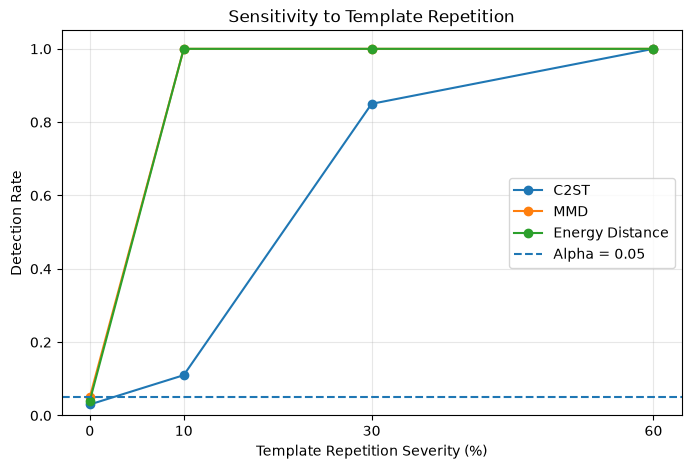

In [30]:
# sensitivity curve 
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for metric in [
    "C2ST",
    "MMD",
    "Energy Distance"
]:

    metric_data = (
        sensitivity_summary_df[
            sensitivity_summary_df["metric"]
            == metric
        ]
        .sort_values("severity")
    )

    plt.plot(
        metric_data["severity"] * 100,
        metric_data["detection_rate"],
        marker="o",
        label=metric
    )

plt.axhline(
    y=ALPHA,
    linestyle="--",
    label="Alpha = 0.05"
)

plt.xlabel("Template Repetition Severity (%)")
plt.ylabel("Detection Rate")
plt.title(
    "Sensitivity to Template Repetition"
)

plt.xticks([0, 10, 30, 60])
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [31]:
# save results
sensitivity_results_df.to_csv(
    "../results/template_repetition_sensitivity_100_runs.csv",
    index=False
)

sensitivity_summary_df.to_csv(
    "../results/template_repetition_sensitivity_100_summary.csv",
    index=False
)

sensitivity_table.to_csv(
    "../results/template_repetition_sensitivity_curve.csv",
    index=False
)


#### Sensitivity Curve Results — Template Repetition

The sensitivity experiment evaluated C2ST, MMD, and Energy Distance at template-repetition severities of 0%, 10%, 30%, and 60%. For each severity, 100 repetitions were performed with 100 observations per group. Within each repetition, all three metrics received exactly the same clean $P$ and defective $Q$ samples, using the same 5,000-feature TF-IDF representation. MMD and Energy Distance used 100 permutations per test. The complete sensitivity experiment took 98.19 seconds.

At 0% severity, the observed rejection rates were 0.03 for C2ST, 0.05 for MMD, and 0.04 for Energy Distance, all close to the expected significance level of $\alpha=0.05$. This indicates that the three tests showed reasonable Type I error behavior when no defect was present. At 10% severity, however, a clear difference appeared: C2ST detected the defect in only 11% of repetitions, whereas both MMD and Energy Distance detected it in 100%. At 30% severity, C2ST power increased substantially to 0.85, while MMD and Energy Distance remained at 1.00. At 60% severity, all three metrics reached an observed power of 1.00.

Overall, the sensitivity curve shows that MMD and Energy Distance are highly sensitive to exact template repetition under the selected TF-IDF representation, detecting even the 10% defect level consistently. C2ST requires a stronger defect before achieving high detection power, showing a gradual increase from 0.11 at 10% to 0.85 at 30% and 1.00 at 60%. The original hypothesis that MMD would be sensitive to template repetition is therefore supported, although Energy Distance performed equally well in this dry run and the two cannot be ranked because both reached saturated power from 10% onward. These conclusions apply specifically to this exact-repetition implementation, TF-IDF representation, sample size, and experimental configuration.

#### Pilot Dry Run Conclusion 

The complete experimental pipeline was successfully executed using template repetition as the first controlled defect. Exact repetition was injected into the UCI SMS Spam Collection at graded severity levels and represented using a shared 5,000-feature TF-IDF space. C2ST, MMD, and Energy Distance were then evaluated under matched conditions. At 0% severity, all three tests showed rejection rates close to the expected $\alpha=0.05$, providing a useful null-condition sanity check. As severity increased, MMD and Energy Distance showed substantially greater sensitivity than C2ST: both reached an observed detection rate of 1.00 at 10% repetition, while C2ST increased from 0.11 at 10% to 0.85 at 30% and 1.00 at 60%. These results support the initial hypothesis that MMD is sensitive to template repetition, while also showing that Energy Distance is highly responsive under the same representation. The dry run therefore confirms that the defect-injection, representation, repeated-testing, power-estimation, and sensitivity-analysis pipeline is operational. These findings are preliminary and specific to the current exact-repetition implementation and experimental configuration; the final study will require a fixed severity plan and higher simulation precision.